
# SAM, USAM, DNSAM and their SDEs on a 2D quadratic

This notebook does the following:

1. simulate the SDE of **SAM**, **USAM**, and **DNSAM**;
2. run the corresponding discrete algorithms;
3. use a two-dimensional quadratic landscape;
4. plot algorithm trajectories together with the trajectories of their SDEs;
5. average everything over `N_RUNS` runs.

We use the constant-covariance stochastic-gradient model
$
\nabla f_\gamma(x) = \nabla f(x) + Z, \qquad Z \sim \mathcal N(0,\Sigma).
$


The quadratic loss is
$
f(x) = \frac12 x^\top Hx, \qquad \nabla f(x)=Hx, \qquad \nabla^2 f(x)=H.
$

In [1]:
import numpy as np
import matplotlib.pyplot as plt

%config InlineBackend.figure_formats = ['svg']

from numpy import linalg as LA

try:
    import seaborn as sns
    colors = sns.color_palette("colorblind")
except Exception:
    colors = plt.rcParams["axes.prop_cycle"].by_key()["color"]

plt.rcParams.update({"font.size": 14})
plt.rcParams["figure.figsize"] = (7, 5)


In [2]:

# Define custom dash patterns for each line without names.
# This follows the style of the provided adaptive-methods notebook.
custom_dashes = [
    (1, 0),              # Solid
    (1, 1),              # Dotted
    (4, 2),              # Dashed
    (3, 2, 1, 2),        # Dash-dot
    (5, 2, 1, 2, 1, 2),  # Dash-dot-dot
    (8, 2),              # Long dashes
    (2, 4),              # Loosely dashed
    (5, 4, 1, 4),        # Sparse dash-dot
    (6, 4, 1, 4, 1, 4),  # Sparse dash-dot-dot
    (1, 4),              # Loosely dotted
    (4, 2, 1, 2, 1, 2),  # Dashed with dots
    (2, 4, 1, 4, 2, 4),  # Custom pattern
]


## Experiment configuration

In [3]:

# -----------------------------
# Main hyperparameters
# -----------------------------
d = 2
eta = 2e-3
rho = np.sqrt(eta)       # Moderate-rho regime: rho = O(sqrt(eta))
T = 5.0
nit = int(T / eta)

N_RUNS = 64
seeds = list(range(N_RUNS))

# Constant covariance of stochastic gradient noise: Z ~ N(0, Sigma).
sigma_grad = 0.35
Sigma = (sigma_grad ** 2) * np.eye(d)
Sigma_sqrt = sigma_grad * np.eye(d)

# Small numerical floor only to prevent division by zero in normalized methods.
NUMERICAL_NORM_FLOOR = 1e-8

# Number of Monte Carlo samples used only for the SAM SDE expectations.
# Increase to 4096/8192 for smoother SAM-SDE trajectories.
SAM_MC_SAMPLES = 1024

# -----------------------------
# Quadratic landscape
# -----------------------------

H = np.array([[10.0, 0.6],
              [0.6,  2.0]])
x0 = np.array([1.0, 1.2])


I = np.eye(d)

print(f"d={d}, eta={eta}, rho={rho:.5f}, T={T}, nit={nit}, N_RUNS={N_RUNS}")
print("H =")
print(H)
print("Sigma =")
print(Sigma)


d=2, eta=0.002, rho=0.04472, T=5.0, nit=2500, N_RUNS=64
H =
[[10.   0.6]
 [ 0.6  2. ]]
Sigma =
[[0.1225 0.    ]
 [0.     0.1225]]


In [4]:

def cost(x):
    """Quadratic objective f(x)=0.5*x^T H x."""
    x = np.asarray(x)
    return 0.5 * x.T @ H @ x

def grad(x):
    """Full gradient of the quadratic objective."""
    x = np.asarray(x)
    return H @ x

def safe_norm(v, floor=NUMERICAL_NORM_FLOOR):
    """Euclidean norm with a small floor for numerical stability."""
    return max(LA.norm(v), floor)

def sample_gradient_noise(rng):
    """Sample Z ~ N(0, Sigma)."""
    return Sigma_sqrt @ rng.normal(size=d)

def sqrt_psd(A, eigen_floor=0.0):
    """
    Symmetric positive-semidefinite square root via eigendecomposition.
    """
    A = 0.5 * (A + A.T)
    vals, vecs = LA.eigh(A)
    vals = np.clip(vals, eigen_floor, None)
    return (vecs * np.sqrt(vals)) @ vecs.T



## Algorithms

The stochastic gradients are generated from the same constant-covariance model at both the ascent and descent evaluations.

For a single noise vector $Z_k$, the updates are:

$
\text{SAM:}\quad x_{k+1}=x_k-\eta\,\nabla f_{\gamma_k}\left(x_k+\rho\frac{\nabla f_{\gamma_k}(x_k)}{\|\nabla f_{\gamma_k}(x_k)\|}\right),
$

$
\text{USAM:}\quad x_{k+1}=x_k-\eta\,\nabla f_{\gamma_k}\left(x_k+\rho\nabla f_{\gamma_k}(x_k)\right),
$

$
\text{DNSAM:}\quad x_{k+1}=x_k-\eta\,\nabla f_{\gamma_k}\left(x_k+\rho\frac{\nabla f_{\gamma_k}(x_k)}{\|\nabla f(x_k)\|}\right).
$


In [5]:

def algorithm_traj(kind, seed):
    """
    Run the true discrete algorithm under the additive constant-covariance
    stochastic-gradient model.

    kind in {"SAM", "USAM", "DNSAM"}.
    """
    rng = np.random.default_rng(seed)

    x = np.zeros((nit + 1, d))
    f = np.zeros(nit + 1)
    x[0] = x0
    f[0] = cost(x[0])

    for k in range(nit):
        z = sample_gradient_noise(rng)
        gx = grad(x[k])

        if kind == "SAM":
            u = gx + z
            perturbation = rho * u / safe_norm(u)

        elif kind == "USAM":
            u = gx + z
            perturbation = rho * u

        elif kind == "DNSAM":
            u = gx + z
            perturbation = rho * u / safe_norm(gx)

        else:
            raise ValueError("kind must be one of {'SAM', 'USAM', 'DNSAM'}.")

        # Same mini-batch/noise z is used for the outer gradient.
        outer_gradient = grad(x[k] + perturbation) + z

        x[k + 1] = x[k] - eta * outer_gradient
        f[k + 1] = cost(x[k + 1])

    return x, f



## SDEs

For the quadratic $f(x)=\frac12x^\top Hx$, the USAM and DNSAM SDEs become particularly simple.

USAM:
$
dX_t=-H(I+\rho H)X_t\,dt+(I+\rho H)(\eta\Sigma)^{1/2}\,dW_t.
$

DNSAM:
$
dX_t=-H\left(I+\rho\frac{H}{\|HX_t\|}\right)X_t\,dt+
\left(I+\rho\frac{H}{\|HX_t\|}\right)(\eta\Sigma)^{1/2}\,dW_t.
$

For SAM, the drift contains the expectation
$
-\nabla\left(f(x)+\rho\,\mathbb E\|Hx+Z\|\right)
= -\left(Hx+\rho H\,\mathbb E\frac{Hx+Z}{\|Hx+Z\|}\right),
$
and the diffusion is estimated by Monte Carlo under the same constant-covariance noise model.


In [6]:
rng_mc = np.random.default_rng(12345)
half = SAM_MC_SAMPLES // 2
Z_half = rng_mc.normal(size=(half, d)) @ Sigma_sqrt.T
Z_MC = np.vstack([Z_half, -Z_half])

def sam_sde_expectations(x):
    """
    Monte Carlo estimate of the SAM SDE drift correction and diffusion covariance.

    Returns:
        mean_dir: E[(Hx+Z)/||Hx+Z||]
        M: covariance matrix inside sqrt(eta * M) dW_t
    """
    gx = grad(x)
    U = gx[None, :] + Z_MC
    norms = LA.norm(U, axis=1, keepdims=True)
    dirs = U / np.maximum(norms, NUMERICAL_NORM_FLOOR)

    mean_dir = dirs.mean(axis=0)
    C = (Z_MC.T @ (dirs - mean_dir[None, :])) / Z_MC.shape[0]
    M = Sigma + rho * (C @ H + H @ C.T)


    M = 0.5 * (M + M.T)
    return mean_dir, M


def sde_traj(kind, seed):
    """
    Euler-Maruyama simulation of the SDE, sampled on the algorithmic grid t_k=k*eta.

    kind in {"SAM", "USAM", "DNSAM"}.
    """
    rng = np.random.default_rng(seed)

    x = np.zeros((nit + 1, d))
    f = np.zeros(nit + 1)
    x[0] = x0
    f[0] = cost(x[0])

    sqrt_dt = np.sqrt(eta)

    for k in range(nit):
        gx = grad(x[k])

        if kind == "USAM":
            A = I + rho * H
            drift = -(H @ A @ x[k])
            diffusion = np.sqrt(eta) * A @ Sigma_sqrt

        elif kind == "DNSAM":
            A = I + rho * H / safe_norm(gx)
            drift = -(H @ A @ x[k])
            diffusion = np.sqrt(eta) * A @ Sigma_sqrt

        elif kind == "SAM":
            mean_dir, M = sam_sde_expectations(x[k])
            drift = -(gx + rho * (H @ mean_dir))
            diffusion = np.sqrt(eta) * sqrt_psd(M)

        else:
            raise ValueError("kind must be one of {'SAM', 'USAM', 'DNSAM'}.")

        dW = sqrt_dt * rng.normal(size=d)
        x[k + 1] = x[k] + eta * drift + diffusion @ dW
        f[k + 1] = cost(x[k + 1])

        if not np.all(np.isfinite(x[k + 1])):
            raise FloatingPointError(
                f"Non-finite value encountered for {kind} SDE at iteration {k}. "
                "Try reducing eta, T, rho, or increasing NUMERICAL_NORM_FLOOR."
            )

    return x, f



## Run all methods and average over 5 runs


In [7]:

def run_many(simulator, kind, seeds):
    trajs = []
    losses = []

    for seed in seeds:
        x, f = simulator(kind, seed)
        trajs.append(x)
        losses.append(f)

    trajs = np.stack(trajs, axis=0)
    losses = np.stack(losses, axis=0)

    return {
        "trajs": trajs,
        "losses": losses,
        "avg_traj": trajs.mean(axis=0),
        "std_traj": trajs.std(axis=0),
        "avg_loss": losses.mean(axis=0),
        "std_loss": losses.std(axis=0),
    }


all_results = {}

for kind in ["SAM", "USAM", "DNSAM"]:
    print(f"Running {kind} algorithm...")
    all_results[f"{kind}"] = run_many(algorithm_traj, kind, seeds)

    print(f"Running {kind} SDE...")
    all_results[f"{kind} SDE"] = run_many(sde_traj, kind, seeds)

print("Done.")


Running SAM algorithm...
Running SAM SDE...
Running USAM algorithm...
Running USAM SDE...
Running DNSAM algorithm...
Running DNSAM SDE...
Done.


In [8]:

# Save results, following the style of the provided notebook.
np.savez(
    "SAM_USAM_DNSAM_Quadratic_Results.npz",
    H=H,
    Sigma=Sigma,
    x0=x0,
    eta=eta,
    rho=rho,
    sigma_grad=sigma_grad,
    T=T,
    nit=nit,
    seeds=np.array(seeds),
    SAM_trajs=all_results["SAM"]["trajs"],
    USAM_trajs=all_results["USAM"]["trajs"],
    DNSAM_trajs=all_results["DNSAM"]["trajs"],
    SAM_SDE_trajs=all_results["SAM SDE"]["trajs"],
    USAM_SDE_trajs=all_results["USAM SDE"]["trajs"],
    DNSAM_SDE_trajs=all_results["DNSAM SDE"]["trajs"],
    SAM_losses=all_results["SAM"]["losses"],
    USAM_losses=all_results["USAM"]["losses"],
    DNSAM_losses=all_results["DNSAM"]["losses"],
    SAM_SDE_losses=all_results["SAM SDE"]["losses"],
    USAM_SDE_losses=all_results["USAM SDE"]["losses"],
    DNSAM_SDE_losses=all_results["DNSAM SDE"]["losses"],
)
print("Saved: SAM_USAM_DNSAM_Quadratic_Results.npz")


Saved: SAM_USAM_DNSAM_Quadratic_Results.npz



## Plot helper functions


In [9]:

method_colors = {
    "USAM": "#0072B2",
    "DNSAM": "#009E73",
    "USAM SDE": "#E69F00",
    "DNSAM SDE": "#D55E00",
    "SAM": "#F781BF",
    "SAM SDE": "#F0E442",
}

method_dashes = {
    "USAM": custom_dashes[0],
    "DNSAM": custom_dashes[0],
    "USAM SDE": custom_dashes[1],
    "DNSAM SDE": custom_dashes[1],
    "SAM": custom_dashes[0],
    "SAM SDE": custom_dashes[1],
}

loss_plot_order = ["USAM", "DNSAM", "USAM SDE", "DNSAM SDE", "SAM", "SAM SDE"]

def make_grid_from_trajectories(results, padding=0.15, grid_points=200):
    all_xy = []
    for key, value in results.items():
        all_xy.append(value["avg_traj"])
    all_xy = np.concatenate(all_xy, axis=0)

    x_min, y_min = all_xy.min(axis=0)
    x_max, y_max = all_xy.max(axis=0)

    x_span = max(x_max - x_min, 1e-3)
    y_span = max(y_max - y_min, 1e-3)

    x_values = np.linspace(x_min - padding * x_span, x_max + padding * x_span, grid_points)
    y_values = np.linspace(y_min - padding * y_span, y_max + padding * y_span, grid_points)

    X, Y = np.meshgrid(x_values, y_values)
    Z = np.zeros_like(X)

    for i in range(X.shape[0]):
        for j in range(X.shape[1]):
            Z[i, j] = cost(np.array([X[i, j], Y[i, j]]))

    return X, Y, Z


def plot_all_average_trajectories(results, plot_individual=True, stride=1):
    X, Y, Z = make_grid_from_trajectories(results)

    plt.figure(figsize=(8, 6))
    contour = plt.contourf(X, Y, Z, levels=40, cmap="coolwarm", alpha=0.75)
    plt.colorbar(contour, label=r"$f(x)$")

    handles = []
    labels = []

    for key in loss_plot_order:
        c = method_colors[key]
        dash = method_dashes[key]

        if plot_individual:
            for r in range(results[key]["trajs"].shape[0]):
                tr = results[key]["trajs"][r]
                plt.plot(tr[::stride, 0], tr[::stride, 1], color=c, alpha=0.08, linewidth=1)

        avg = results[key]["avg_traj"]
        line, = plt.plot(avg[::stride, 0], avg[::stride, 1], color=c, linewidth=3)
        line.set_dashes(dash)
        handles.append(line)
        labels.append(key)

    plt.scatter([x0[0]], [x0[1]], marker="o", s=70, color="black", label="start")
    plt.scatter([0], [0], marker="x", s=70, color="black", label="origin")

    plt.title(f"Averaged trajectories over {N_RUNS} runs")
    plt.xlabel(r"$x_1$")
    plt.ylabel(r"$x_2$")
    plt.legend(handles, labels, fontsize=10, loc="best")
    plt.tight_layout()
    plt.show()


def plot_pairwise_trajectories(results, stride=1):
    kinds = ["SAM", "USAM", "DNSAM"]

    fig, axes = plt.subplots(1, 3, figsize=(18, 5))

    for ax, kind in zip(axes, kinds):
        pair = {kind: results[kind], f"{kind} SDE": results[f"{kind} SDE"]}
        X, Y, Z = make_grid_from_trajectories(pair)
        ax.contourf(X, Y, Z, levels=35, cmap="coolwarm", alpha=0.75)

        for key in [kind, f"{kind} SDE"]:
            avg = results[key]["avg_traj"]
            line, = ax.plot(
                avg[::stride, 0],
                avg[::stride, 1],
                color=method_colors[key],
                linewidth=3,
                label=key,
            )
            line.set_dashes(method_dashes[key])

        ax.scatter([x0[0]], [x0[1]], marker="o", s=60, color="black")
        ax.scatter([0], [0], marker="x", s=60, color="black")
        ax.set_title(kind)
        ax.set_xlabel(r"$x_1$")
        ax.set_ylabel(r"$x_2$")
        ax.legend(fontsize=14, loc="lower right", frameon=True)

    plt.tight_layout()
    plt.show()


def plot_single_trajectory(results, kind, stride=1, filename=None):
    pair = {kind: results[kind], f"{kind} SDE": results[f"{kind} SDE"]}
    X, Y, Z = make_grid_from_trajectories(pair)

    plt.figure(figsize=(8, 6))
    contour = plt.contourf(X, Y, Z, levels=35, cmap="coolwarm", alpha=0.75)

    cbar = plt.colorbar(contour)
    cbar.set_label(r"$f(x)$", fontsize=16)
    cbar.ax.tick_params(labelsize=16)

    for key in [kind, f"{kind} SDE"]:
        avg = results[key]["avg_traj"]
        line, = plt.plot(
            avg[::stride, 0],
            avg[::stride, 1],
            color=method_colors[key],
            linewidth=3,
            label=key,
        )
        line.set_dashes(method_dashes[key])

    plt.scatter([x0[0]], [x0[1]], marker="o", s=60, color="black")
    plt.scatter([0], [0], marker="x", s=60, color="black")

    plt.title(kind, fontsize=16)
    plt.xlabel(r"$x_1$", fontsize=16)
    plt.ylabel(r"$x_2$", fontsize=16)

    plt.tick_params(axis="both", which="major", labelsize=16)
    plt.tick_params(axis="both", which="minor", labelsize=16)

    plt.legend(fontsize=16, loc="lower right", frameon=True)

    plt.tight_layout()

    if filename is not None:
        plt.savefig(filename, bbox_inches="tight")

    plt.show()


def plot_losses(results, start=0, end=None, band_scale=0.25, filename=None, show_band=False):
    if end is None:
        end = nit + 1

    t = np.arange(start, end)

    fig, ax = plt.subplots(figsize=(6.5, 4.8))

    for key in loss_plot_order:
        avg = results[key]["avg_loss"][start:end]
        std = results[key]["std_loss"][start:end]
        c = method_colors[key]

        line, = ax.plot(t, avg, color=c, linewidth=3, label=key)
        line.set_dashes(method_dashes[key])
        if show_band and band_scale is not None and band_scale > 0:
            ax.fill_between(
                t,
                avg - band_scale * std,
                avg + band_scale * std,
                color=c,
                alpha=0.08,
                linewidth=0,
            )

    ax.set_yscale("log")
    ax.set_xlabel(r"Iteration ($k$)", fontsize=16)
    ax.set_ylabel(r"$f(x_k)$", fontsize=16)
    ax.set_title("Loss - Quadratic", fontsize=16)
    ax.tick_params(axis="both", which="major", labelsize=16)
    ax.tick_params(axis="both", which="minor", labelsize=12)
    ax.legend(fontsize=14, loc="upper right", frameon=True)
    fig.tight_layout()

    if filename is not None:
        fig.savefig(filename, bbox_inches="tight")

    plt.show()



## Main plots

The solid lines are discrete algorithms; the dashed lines are the corresponding SDEs.


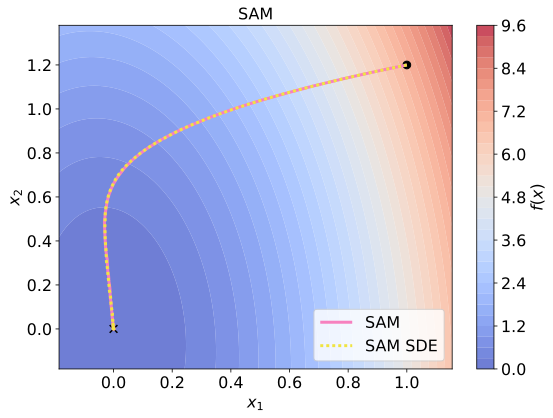

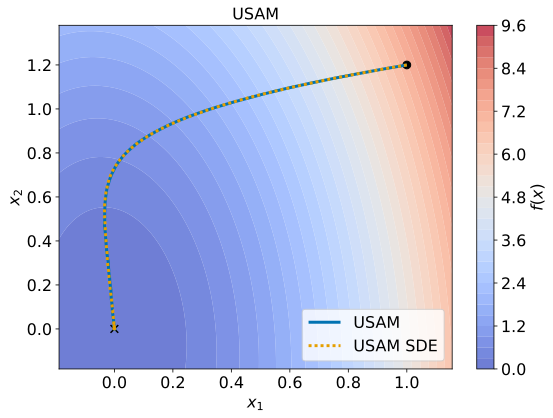

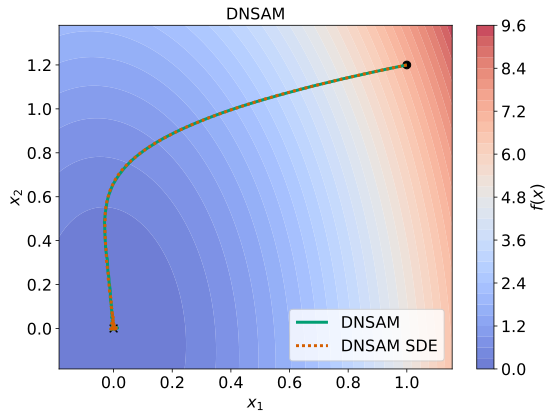

In [10]:
plot_single_trajectory(all_results, "SAM", stride=1, filename="SAM_trajectory.pdf")
plot_single_trajectory(all_results, "USAM", stride=1, filename="USAM_trajectory.pdf")
plot_single_trajectory(all_results, "DNSAM", stride=1, filename="DNSAM_trajectory.pdf")


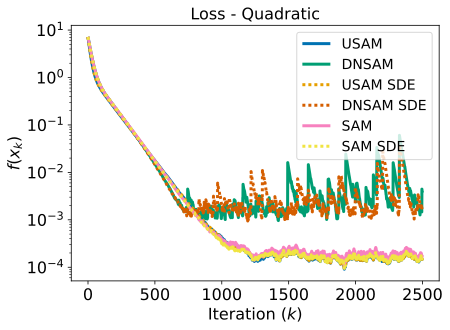

In [11]:
plot_losses(all_results, band_scale=0.05, filename="SAM_USAM_DNSAM_losses.pdf")
